# 6. Model Evaluation

The trained models are compared using the metrics used in the main notebook.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    roc_auc_score,
    classification_report,
    roc_curve
)

processed_data = joblib.load("../data/03_processed_data.pkl")
trained_models = joblib.load("../data/05_trained_models.pkl")

X_train = processed_data["X_train"]
X_test = processed_data["X_test"]
y_train = processed_data["y_train"]
y_test = processed_data["y_test"]
X_test_scaled = processed_data["X_test_scaled"]

logistic_model = trained_models["logistic_model"]
decision_tree_model = trained_models["decision_tree_model"]
random_forest_model = trained_models["random_forest_model"]

y_pred_lr = logistic_model.predict(X_test_scaled)
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Models and test data loaded successfully!")


Models and test data loaded successfully!


## Logistic Regression Evaluation

Confusion Matrix:
[[1240  489]
 [ 276 2935]]


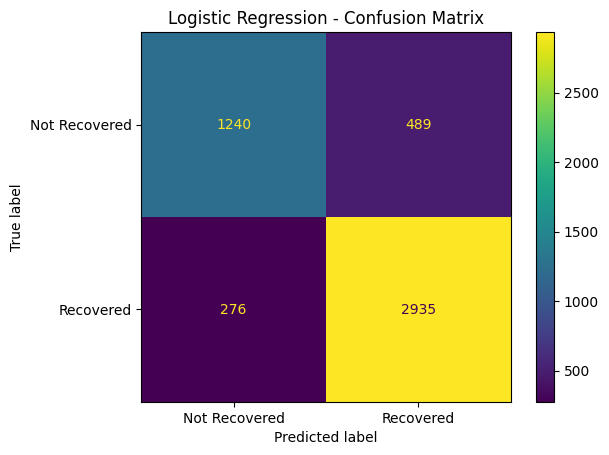

In [2]:

cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Not Recovered", "Recovered"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [3]:
from sklearn.metrics import recall_score

recall_lr = recall_score(y_test, y_pred_lr)

print("Logistic Regression Recall:", recall_lr)

Logistic Regression Recall: 0.9140454687013392


In [4]:
from sklearn.metrics import roc_auc_score

y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression ROC-AUC:", roc_auc_lr)

Logistic Regression ROC-AUC: 0.9180502822588416


In [5]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Not Recovered", "Recovered"]
))

Logistic Regression Classification Report:
               precision    recall  f1-score   support

Not Recovered       0.82      0.72      0.76      1729
    Recovered       0.86      0.91      0.88      3211

     accuracy                           0.85      4940
    macro avg       0.84      0.82      0.82      4940
 weighted avg       0.84      0.85      0.84      4940



## Decision Tree Model

A Decision Tree is a supervised learning algorithm that makes predictions
by splitting the data based on feature values.

It is easy to interpret and can capture non-linear relationships between
customer characteristics and loan recovery.

## Decision Tree Model

A Decision Tree is a supervised learning algorithm that makes predictions
by splitting the data based on feature values.

It is easy to interpret and can capture non-linear relationships between
customer characteristics and loan recovery.

In [6]:
print("Using the saved Decision Tree model.")

Using the saved Decision Tree model.


In [7]:
y_pred_dt = decision_tree_model.predict(X_test)

print("Decision Tree predictions generated successfully!")
print("Number of predictions:", len(y_pred_dt))

Decision Tree predictions generated successfully!
Number of predictions: 4940


Decision Tree Confusion Matrix:
[[1199  530]
 [ 287 2924]]


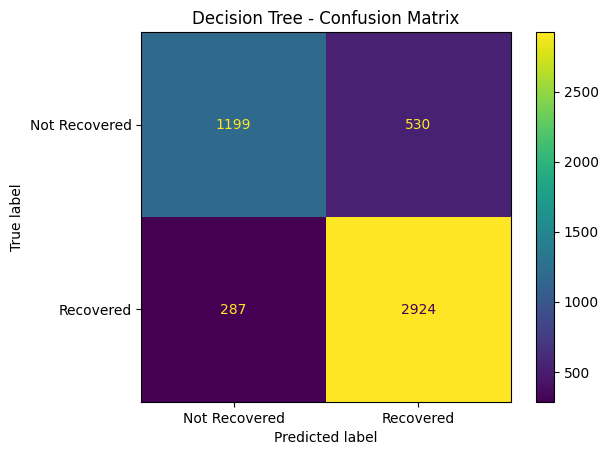

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Not Recovered", "Recovered"]
).plot()

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [9]:
from sklearn.metrics import recall_score

recall_dt = recall_score(y_test, y_pred_dt)

print("Decision Tree Recall:", recall_dt)

Decision Tree Recall: 0.9106197446278418


In [10]:
from sklearn.metrics import roc_auc_score

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree ROC-AUC:", roc_auc_dt)

Decision Tree ROC-AUC: 0.8985512676115703


In [11]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report:")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Not Recovered", "Recovered"]
))

Decision Tree Classification Report:
               precision    recall  f1-score   support

Not Recovered       0.81      0.69      0.75      1729
    Recovered       0.85      0.91      0.88      3211

     accuracy                           0.83      4940
    macro avg       0.83      0.80      0.81      4940
 weighted avg       0.83      0.83      0.83      4940



## Random Forest Model

Random Forest is an ensemble learning algorithm that combines multiple
Decision Trees to make a more reliable prediction.

It generally provides better performance and reduces overfitting compared
with using a single Decision Tree.

In [12]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=8
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))

Random Forest predictions generated successfully!
Number of predictions: 4940


Random Forest Confusion Matrix:
[[1195  534]
 [ 262 2949]]


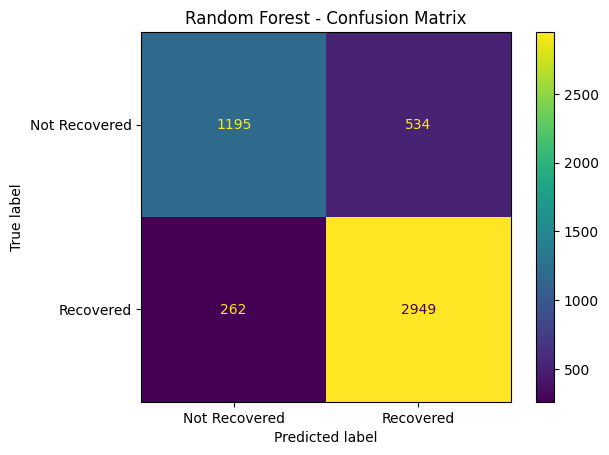

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Not Recovered", "Recovered"]
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [15]:
from sklearn.metrics import recall_score

recall_rf = recall_score(y_test, y_pred_rf)

print("Random Forest Recall:", recall_rf)

Random Forest Recall: 0.9184054811585176


In [16]:
from sklearn.metrics import roc_auc_score

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.9134364791071179


In [17]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Not Recovered", "Recovered"]
))

Random Forest Classification Report:
               precision    recall  f1-score   support

Not Recovered       0.82      0.69      0.75      1729
    Recovered       0.85      0.92      0.88      3211

     accuracy                           0.84      4940
    macro avg       0.83      0.80      0.82      4940
 weighted avg       0.84      0.84      0.84      4940



## ROC Curve Comparison

The ROC curve shows the relationship between the True Positive Rate
and False Positive Rate at different classification thresholds.

ROC-AUC summarizes the overall ability of each model to distinguish
between recovered and non-recovered loans.

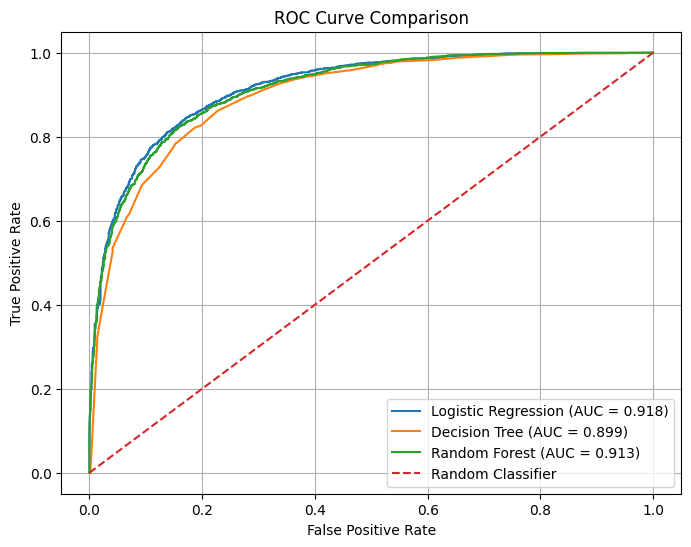

In [18]:
from sklearn.metrics import roc_curve

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {roc_auc_dt:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.3f})"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

### Model Comparison

In [19]:

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Recall": [recall_lr, recall_dt, recall_rf],
    "ROC-AUC": [roc_auc_lr, roc_auc_dt, roc_auc_rf],
    "Accuracy": [
        (y_pred_lr == y_test).mean(),
        (y_pred_dt == y_test).mean(),
        (y_pred_rf == y_test).mean()
    ]
})

comparison


,Model,Recall,ROC-AUC,Accuracy
0,Logistic Regression,0.914045,0.918050,0.845142
1,Decision Tree,0.910620,0.898551,0.834615
2,Random Forest,0.918405,0.913436,0.838866


In [20]:

comparison.to_csv("../data/06_model_comparison.csv", index=False)
print("Model comparison saved successfully!")


Model comparison saved successfully!


## Recall and ROC-AUC Optimization

For this project, Recall and ROC-AUC are the main evaluation metrics.

Recall measures how many of the actual recovered loans are correctly
identified by the model. A high recall is useful because missing a loan
that could potentially be recovered may result in a missed recovery
opportunity.

ROC-AUC measures how well the model separates recovered and non-recovered
loans across different classification thresholds.

The default classification threshold is 0.50. However, different
thresholds can change the balance between correctly identified recovery
cases and false positives.

Therefore, threshold analysis is performed on the final Random Forest
model to understand whether a different threshold provides a useful
trade-off for the debt recovery strategy.

In [21]:
import numpy as np
from sklearn.metrics import recall_score, roc_auc_score, precision_score

# Get recovery probabilities from the final Random Forest model
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# ROC-AUC does not depend on the classification threshold
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", round(roc_auc_rf, 4))

# Check different probability thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

print("\nThreshold Analysis:")
print("Threshold | Recall | Precision")

for threshold in thresholds:
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    recall = recall_score(y_test, y_pred_threshold)
    precision = precision_score(y_test, y_pred_threshold)

    print(
        threshold,
        "|",
        round(recall, 4),
        "|",
        round(precision, 4)
    )

Random Forest ROC-AUC: 0.9134

Threshold Analysis:
Threshold | Recall | Precision
0.3 | 0.9751 | 0.7796
0.4 | 0.9511 | 0.814
0.5 | 0.9184 | 0.8467
0.6 | 0.8729 | 0.8814
0.7 | 0.7932 | 0.9155


## Model Testing with Recovery and Non-Recovery Cases

To validate the practical behavior of the trained model, sample cases from
the test dataset are evaluated.

Both recovered and non-recovered loan cases are selected and their predicted
recovery probabilities are compared with their actual outcomes.

This provides a simple practical validation of whether the model produces
meaningful recovery probability scores.

In [22]:
# Select a few actual recovery and non-recovery cases

test_results = X_test.copy()

test_results["Actual"] = y_test.values
test_results["Recovery_Probability"] = y_prob_rf
test_results["Predicted"] = (y_prob_rf >= 0.50).astype(int)

print("Sample Recovery Cases")
print("---------------------")
print(
    test_results[test_results["Actual"] == 1][
        ["Actual", "Recovery_Probability", "Predicted"]
    ].head(5)
)

print("\nSample Non-Recovery Cases")
print("-------------------------")
print(
    test_results[test_results["Actual"] == 0][
        ["Actual", "Recovery_Probability", "Predicted"]
    ].head(5)
)

Sample Recovery Cases
---------------------
       Actual  Recovery_Probability  Predicted
23515       1              0.847659          1
5707        1              0.985294          1
5510        1              0.944015          1
23819       1              0.587457          1
7570        1              0.764346          1

Sample Non-Recovery Cases
-------------------------
       Actual  Recovery_Probability  Predicted
8278        0              0.360892          0
22466       0              0.280268          0
3601        0              0.720485          1
4331        0              0.283553          0
10544       0              0.544885          1


### Test Case Interpretation

The test cases demonstrate how the model converts borrower and loan
characteristics into a recovery probability.

Cases with higher predicted probabilities are more likely to be classified
as recovered, while cases with lower probabilities are more likely to be
classified as non-recovered.

These predictions can be used as decision-support information for prioritizing
debt recovery activities.

In [23]:
comparison

,Model,Recall,ROC-AUC,Accuracy
0,Logistic Regression,0.914045,0.918050,0.845142
1,Decision Tree,0.910620,0.898551,0.834615
2,Random Forest,0.918405,0.913436,0.838866


In [24]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Recall": [0.914045, 0.910620, 0.918405],
    "ROC-AUC": [0.918050, 0.898551, 0.913436],
    "Accuracy": [0.845142, 0.834615, 0.838866]
})

display(comparison)

,Model,Recall,ROC-AUC,Accuracy
0,Logistic Regression,0.914045,0.918050,0.845142
1,Decision Tree,0.910620,0.898551,0.834615
2,Random Forest,0.918405,0.913436,0.838866


In [25]:
comparison.to_csv("../data/06_model_comparison.csv", index=False)

print("Model comparison saved successfully! ✅")

Model comparison saved successfully! ✅
